 Влияние масштаба признака на обучение с SGD

вопрос: если перевести координату из метров в сантиметры, придётся ли менять шаг обучения? Для проверки я взял простую зависимость $y=2x+0.5$. Так заранее известно, какой прогноз должна давать модель.

В выборке 101 точка от −1 до 1 метра. Для каждого варианта использую один линейный нейрон в PyTorch, нулевые начальные вес и смещение. За один шаг SGD модель обрабатывает всю выборку. Качество оцениваю по средней квадратичной ошибке (MSE).

In [ ]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from IPython.display import display

x_m = torch.linspace(-1, 1, 101, dtype=torch.float64).reshape(-1, 1)
x_cm = 100 * x_m
y = 2 * x_m + 0.5
x_std = (x_cm - x_cm.mean()) / x_cm.std(unbiased=False)
display(pd.DataFrame({"метры": x_m[::25, 0].tolist(),
                      "сантиметры": x_cm[::25, 0].tolist(),
                      "показание": y[::25, 0].tolist()}))

,метры,сантиметры,показание
0,-1.000000e+00,-1.000000e+02,-1.5
1,-5.000000e-01,-5.000000e+01,-0.5
2,-2.081668e-17,-2.081668e-15,0.5
3,5.000000e-01,5.000000e+01,1.5
4,1.000000e+00,1.000000e+02,2.5


 Первый шаг SGD

Сначала сравню прогнозы для одной точки: $x=1$ м, или $100$ см. Её целевое значение равно 2.5. В начале обе модели дают ноль. Ниже я вывожу градиенты и значения параметров после одного обновления с шагом 0.1.

In [ ]:
def new_model():
    model = nn.Linear(1, 1, dtype=torch.float64)
    with torch.no_grad():
        model.weight.zero_()
        model.bias.zero_()
    return model

loss_fn = nn.MSELoss()

def first_step(x):
    model = new_model()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
    optimizer.zero_grad()
    loss_fn(model(x), y).backward()
    grad = model.weight.grad.item()
    grad_b = model.bias.grad.item()
    optimizer.step()
    assert math.isclose(model.weight.item(), -0.1 * grad, abs_tol=1e-12)
    return {"градиент w": grad, "градиент b": grad_b,
            "новый w": model.weight.item(), "новый b": model.bias.item(),
            "прогноз справа": model(x[-1:]).item()}

display(pd.DataFrame({"метры": first_step(x_m),
                      "сантиметры": first_step(x_cm)}).T.round(5))

,градиент w,градиент b,новый w,новый b,прогноз справа
метры,-1.36,-1.0,0.136,0.1,0.236
сантиметры,-136.00,-1.0,13.600,0.1,1360.100


При переходе к сантиметрам градиент по весу увеличивается по модулю в 100 раз: с −1.36 до −136. Это следует из формулы градиента $2\,\mathrm{mean}((wx+b-y)x)$: начальная ошибка у обеих моделей одинакова, а вход $x$ во второй модели в 100 раз больше.

Для метров первый прогноз в выбранной точке равен $0.136 \cdot 1 + 0.1 = 0.236$. Для сантиметров получается $13.6 \cdot 100 + 0.1 = 1360.1$. В пересчёте на одну и ту же точку вклад веса вырос в 10 000 раз.

Сравнение четырёх вариантов

Я оставил вариант с метрами для сравнения. Для сантиметров взял исходный шаг 0.1, затем уменьшил его в 10 000 раз. В четвёртом варианте стандартизовал координату и вернул шаг 0.1.

На каждый запуск отвожу 100 обновлений. Если MSE превышает $10^{12}$, останавливаю расчёт и фиксирую номер шага. Прогнозы на втором графике показываю в общей системе координат - в метрах.

In [ ]:
def train(x, lr, steps=100):
    model = new_model()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = []
    for step in range(steps + 1):
        loss = loss_fn(model(x), y)
        history.append(loss.item())
        if history[-1] > 1e12 or step == steps:
            break
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model, history

cases = [
    ("Метры", x_m, 0.1),
    ("Сантиметры", x_cm, 0.1),
    ("Сантиметры, малый шаг", x_cm, 0.00001),
    ("Сантиметры, стандартизация", x_std, 0.1),
]
results = {}
rows = []
for name, x, lr in cases:
    model, history = train(x, lr)
    with torch.no_grad():
        prediction = model(x).flatten()
    results[name] = (history, prediction)
    rows.append({"вариант": name, "lr": lr, "обновления": len(history) - 1,
                 "MSE": history[-1], "прогноз при x=0": prediction[50].item(),
                 "состояние": "расходимость" if history[-1] > 1e12 else "100 шагов"})
display(pd.DataFrame(rows).set_index("вариант"))

,lr,обновления,MSE,прогноз при x=0,состояние
вариант,,,,,
Метры,0.10000,100,1.039253e-06,0.500000,100 шагов
Сантиметры,0.10000,3,1.332777e+17,0.244000,расходимость
"Сантиметры, малый шаг",0.00001,100,2.490030e-01,0.000999,100 шагов
"Сантиметры, стандартизация",0.10000,100,6.680727e-20,0.500000,100 шагов


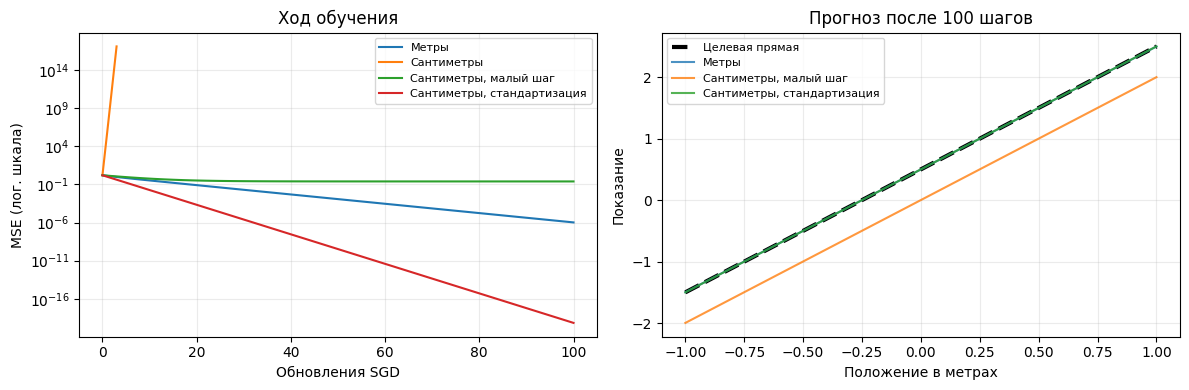

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[1].plot(x_m.flatten(), y.flatten(), "k--", lw=3, label="Целевая прямая")
for name, (history, prediction) in results.items():
    axes[0].semilogy(history, label=name)
    if history[-1] <= 1e12:
        axes[1].plot(x_m.flatten(), prediction, label=name, alpha=0.8)
axes[0].set(xlabel="Обновления SGD", ylabel="MSE (лог. шкала)", title="Ход обучения")
axes[1].set(xlabel="Положение в метрах", ylabel="Показание", title="Прогноз после 100 шагов")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Вывод

При шаге 0.1 за 100 обновлений ошибка модели с координатой в метрах снижается примерно до $1.04\cdot10^{-6}$. После перевода в сантиметры при том же шаге ошибка превышает порог уже на третьем обновлении.

Снижение шага до 0.00001 помогает подобрать наклон, но прямая на графике остаётся ниже целевой. Причину удобно проверить в точке $x=0$: там прогноз равен смещению. За 100 шагов оно доходит примерно до 0.001 при правильном значении 0.5. Маленький шаг замедляет обновление обоих параметров.

Для этих данных я бы выбрал стандартизацию. С ней можно сохранить шаг 0.1, и за те же 100 обновлений модель успевает подобрать и наклон, и смещение. Из этого опыта видно, почему при выборе шага SGD стоит учитывать единицы измерения входных признаков.